# Предобработка данных: преобразование выручки и движения из широкого формата в длинный

**Цель:** Преобразовать исходные Excel-файлы с многоуровневыми заголовками (`Выручка.xlsx`, файл движения по количеству и себестоимости) в единый длинный формат (long format) с колонками `Код`, `Номенклатура`, `Дата`, `Выручка` / `Приход` / `Расход` / `Остатки`; привести даты к формату `datetime`; добавить категории товаров и подготовить данные для дальнейшего ABC/XYZ-анализа и план-факт анализа.

**Вход:**
- `Выручка.xlsx` — широкая таблица выручки с многоуровневым заголовком (месяц × показатель).
- Файл движения (остатки, приход, расход, себестоимость) в аналогичном широком формате.

**Основные шаги:**
1. Чтение Excel с многоуровневыми заголовками (`header=[0, 1]`).
2. Удаление итоговой строки «Итого».
3. Выделение подтаблиц по показателю (Выручка, Начальный остаток, Приход, Расход, Себестоимость).
4. Преобразование широкого формата в длинный через `melt`.
5. Приведение столбца `Дата` к `datetime`.
6. Объединение всех подтаблиц по ключам `Код`, `Номенклатура`, `Ед_изм`, `Дата`.
7. Парсинг русскоязычных названий месяцев («Январь 2021 г.») в даты формата `YYYY-MM-DD`.
8. Сравнение уникальных кодов между выручкой и движением; проверка пересечений.
9. Присвоение категории товара на основе названия номенклатуры (СКЛАД / ПОД ЗАКАЗ / прочее).
10. Сохранение подготовленных данных в промежуточные Excel/CSV-файлы для последующих ноутбуков.

**Навыки:** pandas, numpy, работа с многоуровневыми заголовками (`MultiIndex`), `melt`, `merge`, обработка дат и текста, подготовка данных для аналитики.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [3]:
df = pd.read_excel('Выручка.xlsx', header=[0, 1])  # Читаем с многоуровневыми заголовками
df

,Номенклатура.Код,Номенклатура,2021-01-01 00:00:00,2021-01-02 00:00:00,2021-01-03 00:00:00,2021-02-01 00:00:00,2021-02-02 00:00:00,2021-02-03 00:00:00,2021-03-01 00:00:00,2021-03-02 00:00:00,...,2024-12-03 00:00:00,2025-01-01 00:00:00,2025-01-02 00:00:00,2025-01-03 00:00:00,2025-02-01 00:00:00,2025-02-02 00:00:00,2025-02-03 00:00:00,2025-03-01 00:00:00,2025-03-02 00:00:00,2025-03-03 00:00:00
,Unnamed: 0_level_1,Unnamed: 1_level_1,Количество,Выручка,Себестоимость товаров,Количество,Выручка,Себестоимость товаров,Количество,Выручка,...,Себестоимость товаров,Количество,Выручка,Себестоимость товаров,Количество,Выручка,Себестоимость товаров,Количество,Выручка,Себестоимость товаров
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,2,2287.96,1454.35,114,93177.72,80948.82,72,58005.47,...,0.00,152,250485.68,232063.78,56,106886.63,83631.74,0,0.00,0.00
1,00-00000029,Бак 1500 Combi W BW (сине-белый) для воды с по...,0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,1,45656.67,28527.85
2,00-00000030,Бак 1100 Combi W BW (сине-белый) для воды с по...,0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,0,0.00,0.00
3,00-00000054,я33 200х1400 RCV Purmo (1931 вт 90/70/20) ПОД...,0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,0,0.00,0.00
4,00-00000063,яШайба М 20 оцинк. усиленная ПОД ЗАКАЗ,0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,0,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14181,0Т-00056196,Насосная станция SCA MINI с частотным преобраз...,0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,1,20715.00,14500.83
14182,0Т-00056212,"яКлапан 3/4""x1""пред. для водоснабжения 6 бар ...",0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,1,445.48,356.23
14183,26108,яАмериканка 1/2 прямая латунь 151 Itap ПОД ЗАКАЗ,0,0.00,0.00,0,0.00,0.00,0,0.00,...,0.00,0,0.00,0.00,0,0.00,0.00,0,0.00,0.00


In [5]:
df.columns

MultiIndex([( 'Номенклатура.Код',    'Unnamed: 0_level_1'),
            (     'Номенклатура',    'Unnamed: 1_level_1'),
            (2021-01-01 00:00:00,            'Количество'),
            (2021-01-02 00:00:00,               'Выручка'),
            (2021-01-03 00:00:00, 'Себестоимость товаров'),
            (2021-02-01 00:00:00,            'Количество'),
            (2021-02-02 00:00:00,               'Выручка'),
            (2021-02-03 00:00:00, 'Себестоимость товаров'),
            (2021-03-01 00:00:00,            'Количество'),
            (2021-03-02 00:00:00,               'Выручка'),
            ...
            (2024-12-03 00:00:00, 'Себестоимость товаров'),
            (2025-01-01 00:00:00,            'Количество'),
            (2025-01-02 00:00:00,               'Выручка'),
            (2025-01-03 00:00:00, 'Себестоимость товаров'),
            (2025-02-01 00:00:00,            'Количество'),
            (2025-02-02 00:00:00,               'Выручка'),
            (2025-02-03 

In [4]:
# Удаляем последнюю строку с итогом
df = df.drop(df.tail(1).index)

In [7]:
#создаем df с выручкой!!!
df_amount = df.loc[:, 
    (df.columns.get_level_values(0).isin(['Номенклатура.Код', 'Номенклатура'])) |
    (df.columns.get_level_values(1) == "Выручка")
]

In [8]:
df_amount.columns.tolist()

[('Номенклатура.Код', 'Unnamed: 0_level_1'),
 ('Номенклатура', 'Unnamed: 1_level_1'),
 (datetime.datetime(2021, 1, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 2, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 3, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 4, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 5, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 6, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 7, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 8, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 9, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 10, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 11, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2021, 12, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2022, 1, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2022, 2, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2022, 3, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2022, 4, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2022, 5, 2, 0, 0), 'Выручка'),
 (datetime.datetime(2022, 6, 2, 0, 0), 'Выру

In [9]:
df_amount.columns = df_amount.columns.droplevel(1)

In [10]:
df_amount

,Номенклатура.Код,Номенклатура,2021-01-02 00:00:00,2021-02-02 00:00:00,2021-03-02 00:00:00,2021-04-02 00:00:00,2021-05-02 00:00:00,2021-06-02 00:00:00,2021-07-02 00:00:00,2021-08-02 00:00:00,...,2024-06-02 00:00:00,2024-07-02 00:00:00,2024-08-02 00:00:00,2024-09-02 00:00:00,2024-10-02 00:00:00,2024-11-02 00:00:00,2024-12-02 00:00:00,2025-01-02 00:00:00,2025-02-02 00:00:00,2025-03-02 00:00:00
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,2287.96,93177.72,58005.47,57718.98,24137.17,17179.24,15393.87,75469.85,...,0.00,30930.3,90496.0,0.0,56590.16,0.0,0.0,250485.68,106886.63,0.00
1,00-00000029,Бак 1500 Combi W BW (сине-белый) для воды с по...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,45656.67
2,00-00000030,Бак 1100 Combi W BW (сине-белый) для воды с по...,0.00,0.00,0.00,0.00,12058.15,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00
3,00-00000054,я33 200х1400 RCV Purmo (1931 вт 90/70/20) ПОД...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00
4,00-00000063,яШайба М 20 оцинк. усиленная ПОД ЗАКАЗ,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14180,0Т-00056173,яРеле давления LР/3 (датчик сухого хода) ПОД З...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,592.62
14181,0Т-00056196,Насосная станция SCA MINI с частотным преобраз...,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,20715.00
14182,0Т-00056212,"яКлапан 3/4""x1""пред. для водоснабжения 6 бар ...",0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,0.00,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,445.48
14183,26108,яАмериканка 1/2 прямая латунь 151 Itap ПОД ЗАКАЗ,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,...,362.65,0.0,0.0,0.0,0.00,0.0,0.0,0.00,0.00,0.00


In [11]:
df_1_long = df_amount.melt(id_vars=['Номенклатура.Код', 'Номенклатура'], var_name='Дата', value_name='Выручка')

In [12]:
df_1_long

,Номенклатура.Код,Номенклатура,Дата,Выручка
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,2021-01-02 00:00:00,2287.96
1,00-00000029,Бак 1500 Combi W BW (сине-белый) для воды с по...,2021-01-02 00:00:00,0.00
2,00-00000030,Бак 1100 Combi W BW (сине-белый) для воды с по...,2021-01-02 00:00:00,0.00
3,00-00000054,я33 200х1400 RCV Purmo (1931 вт 90/70/20) ПОД...,2021-01-02 00:00:00,0.00
4,00-00000063,яШайба М 20 оцинк. усиленная ПОД ЗАКАЗ,2021-01-02 00:00:00,0.00
...,...,...,...,...
723430,0Т-00056173,яРеле давления LР/3 (датчик сухого хода) ПОД З...,2025-03-02 00:00:00,592.62
723431,0Т-00056196,Насосная станция SCA MINI с частотным преобраз...,2025-03-02 00:00:00,20715.00
723432,0Т-00056212,"яКлапан 3/4""x1""пред. для водоснабжения 6 бар ...",2025-03-02 00:00:00,445.48
723433,26108,яАмериканка 1/2 прямая латунь 151 Itap ПОД ЗАКАЗ,2025-03-02 00:00:00,0.00


In [15]:
# Преобразуем столбец 'Дата' в формат datetime
df_1_long['Дата'] = pd.to_datetime(df_1_long['Дата'], format='%Y-%m-%d %H:%M:%S')

In [19]:
df_1_long.columns = ['Код', 'Номенклатура', 'Дата', 'Выручка']

In [20]:
df_1_long

,Код,Номенклатура,Дата,Выручка
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,2021-01-02,2287.96
1,00-00000029,Бак 1500 Combi W BW (сине-белый) для воды с по...,2021-01-02,0.00
2,00-00000030,Бак 1100 Combi W BW (сине-белый) для воды с по...,2021-01-02,0.00
3,00-00000054,я33 200х1400 RCV Purmo (1931 вт 90/70/20) ПОД...,2021-01-02,0.00
4,00-00000063,яШайба М 20 оцинк. усиленная ПОД ЗАКАЗ,2021-01-02,0.00
...,...,...,...,...
723430,0Т-00056173,яРеле давления LР/3 (датчик сухого хода) ПОД З...,2025-03-02,592.62
723431,0Т-00056196,Насосная станция SCA MINI с частотным преобраз...,2025-03-02,20715.00
723432,0Т-00056212,"яКлапан 3/4""x1""пред. для водоснабжения 6 бар ...",2025-03-02,445.48
723433,26108,яАмериканка 1/2 прямая латунь 151 Itap ПОД ЗАКАЗ,2025-03-02,0.00


### ЗДЕСЬ ЗАКАНЧИВАЕТСЯ ПРЕОБРАЗОВАНИЕ ВЫРУЧКИ

# Сравнение уникальных кодов номенклатуры в выручке и движении

In [23]:
df_final = pd.read_excel('df_final_движение_СЕБЕСТОИМОСТЬ.xlsx')
df_final.head()

,Код,Номенклатура,Ед_изм,Дата,Начальный_остаток,Приход,Расход,Конечный_остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-08-01,20379.08,48774.81,56835.83,25834.47
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2022-08-01,0.00,86530.76,86530.76,0.00
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2023-08-01,0.00,30935.01,30935.01,0.00
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2024-08-01,0.00,59738.32,59738.32,0.00
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,2021-04-01,61571.85,7941.28,46342.08,23171.05


In [24]:
df_1_long.head()

,Код,Номенклатура,Дата,Выручка
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,2021-01-02,2287.96
1,00-00000029,Бак 1500 Combi W BW (сине-белый) для воды с по...,2021-01-02,0.00
2,00-00000030,Бак 1100 Combi W BW (сине-белый) для воды с по...,2021-01-02,0.00
3,00-00000054,я33 200х1400 RCV Purmo (1931 вт 90/70/20) ПОД...,2021-01-02,0.00
4,00-00000063,яШайба М 20 оцинк. усиленная ПОД ЗАКАЗ,2021-01-02,0.00


In [25]:
print('Количество уникальных кодов в ВЫРУЧКЕ', df_1_long['Код'].nunique())
print('Количество уникальных кодов в РАСХОДЕ', df_final['Код'].nunique())

Количество уникальных кодов в ВЫРУЧКЕ 14185
Количество уникальных кодов в РАСХОДЕ 15445


In [30]:
print('Количество уникальных кодов в ВЫРУЧКЕ', df_1_long['Дата'].nunique())
print('Количество уникальных кодов в РАСХОДЕ', df_final['Дата'].nunique())

Количество уникальных кодов в ВЫРУЧКЕ 51
Количество уникальных кодов в РАСХОДЕ 51


In [31]:
unique_codes_final = set(df_final['Дата'].unique())  # Уникальные коды из первого датасета
unique_codes_revenue = set(df_1_long['Дата'].unique())  # Уникальные коды из второго датасета

codes_only_in_final = unique_codes_final - unique_codes_revenue  # Разность множеств
print("Коды, которые есть в РАСХОДЕ, но нет в ВЫРУЧКЕ:")
print(len(codes_only_in_final))

codes_only_in_revenue = unique_codes_revenue - unique_codes_final
print("Коды, которые есть в ВЫРУЧКЕ, но нет в РАСХОДЕ:")
print(len(codes_only_in_revenue))

#Коды, которые есть в обоих датасетах:
common_codes = unique_codes_final & unique_codes_revenue
len(common_codes)

Коды, которые есть в РАСХОДЕ, но нет в ВЫРУЧКЕ:
51
Коды, которые есть в ВЫРУЧКЕ, но нет в РАСХОДЕ:
51


0

In [35]:
df_1_long['Дата'].unique()
df_final['Дата'].unique()

<DatetimeArray>
['2021-08-01 00:00:00', '2022-08-01 00:00:00', '2023-08-01 00:00:00',
 '2024-08-01 00:00:00', '2021-04-01 00:00:00', '2022-04-01 00:00:00',
 '2023-04-01 00:00:00', '2024-04-01 00:00:00', '2021-12-01 00:00:00',
 '2022-12-01 00:00:00', '2023-12-01 00:00:00', '2024-12-01 00:00:00',
 '2021-07-01 00:00:00', '2022-07-01 00:00:00', '2023-07-01 00:00:00',
 '2024-07-01 00:00:00', '2021-06-01 00:00:00', '2022-06-01 00:00:00',
 '2023-06-01 00:00:00', '2024-06-01 00:00:00', '2021-05-01 00:00:00',
 '2022-05-01 00:00:00', '2023-05-01 00:00:00', '2024-05-01 00:00:00',
 '2021-03-01 00:00:00', '2022-03-01 00:00:00', '2023-03-01 00:00:00',
 '2024-03-01 00:00:00', '2025-03-01 00:00:00', '2021-11-01 00:00:00',
 '2022-11-01 00:00:00', '2023-11-01 00:00:00', '2024-11-01 00:00:00',
 '2021-10-01 00:00:00', '2022-10-01 00:00:00', '2023-10-01 00:00:00',
 '2024-10-01 00:00:00', '2021-09-01 00:00:00', '2022-09-01 00:00:00',
 '2023-09-01 00:00:00', '2024-09-01 00:00:00', '2021-02-01 00:00:00',
 '20

In [28]:
unique_codes_final = set(df_final['Код'].unique())  # Уникальные коды из первого датасета
unique_codes_revenue = set(df_1_long['Код'].unique())  # Уникальные коды из второго датасета

codes_only_in_final = unique_codes_final - unique_codes_revenue  # Разность множеств
print("Коды, которые есть в РАСХОДЕ, но нет в ВЫРУЧКЕ:")
print(len(codes_only_in_final))

codes_only_in_revenue = unique_codes_revenue - unique_codes_final
print("Коды, которые есть в ВЫРУЧКЕ, но нет в РАСХОДЕ:")
print(len(codes_only_in_revenue))

#Коды, которые есть в обоих датасетах:
common_codes = unique_codes_final & unique_codes_revenue
len(common_codes)

Коды, которые есть в РАСХОДЕ, но нет в ВЫРУЧКЕ:
1260
Коды, которые есть в ВЫРУЧКЕ, но нет в РАСХОДЕ:
0


14185

In [ ]:
# Супер! просто добавляем!

In [12]:
# Определяем общий столбец для объединения (например, ['Артикул', 'Номенклатура', 'Ед. изм.', 'Дата'])
common_columns = ['Артикул', 'Номенклатура', 'Ед. изм.', 'Дата']

# Объединяем все датасеты по этим столбцам
df_final = df_1_long.merge(df_2_long, on=common_columns, how="outer", suffixes=('', '_2'))\
                    .merge(df_3_long, on=common_columns, how="outer", suffixes=('', '_3'))\
                    .merge(df_4_long, on=common_columns, how="outer", suffixes=('', '_4'))
df_final.head()

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный остаток,Приход,Расход,Конечный остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2021 г.,24.0,56.0,66.0,30.0
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2022 г.,0.0,76.0,76.0,0.0
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2023 г.,0.0,20.0,20.0,0.0
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2024 г.,0.0,40.0,40.0,0.0
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Апрель 2021 г.,88.0,8.0,64.0,32.0


In [13]:
#df_final.isna().sum()
print(df_final.duplicated(subset=common_columns).sum())
print(df_1_long.duplicated(subset=common_columns).sum())

0
0


In [14]:
df_final

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный остаток,Приход,Расход,Конечный остаток
0,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2021 г.,24.0,56.0,66.0,30.0
1,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2022 г.,0.0,76.0,76.0,0.0
2,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2023 г.,0.0,20.0,20.0,0.0
3,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Август 2024 г.,0.0,40.0,40.0,0.0
4,00-00000019,Труба 75 Базальт ЭКО 8.4 упак 8 м кратно ...,м,Апрель 2021 г.,88.0,8.0,64.0,32.0
...,...,...,...,...,...,...,...,...
787690,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2021 г.,8.0,10.0,3.0,15.0
787691,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2022 г.,8.0,0.0,0.0,8.0
787692,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2023 г.,7.0,0.0,3.0,4.0
787693,ЦБ-00000057,Зонт 50 вентиляционный Контур СКЛАД (10),шт,Январь 2024 г.,5.0,0.0,0.0,5.0


In [15]:
df_final.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 787695 entries, 0 to 787694
Data columns (total 8 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Артикул            787695 non-null  object 
 1   Номенклатура       787695 non-null  object 
 2   Ед. изм.           787695 non-null  object 
 3   Дата               787695 non-null  object 
 4   Начальный остаток  787695 non-null  float64
 5   Приход             787695 non-null  float64
 6   Расход             787695 non-null  float64
 7   Конечный остаток   787695 non-null  float64
dtypes: float64(4), object(4)
memory usage: 48.1+ MB


In [16]:
# Создаём словарь соответствий русских месяцев
months_dict = {
    "Январь": "01", "Февраль": "02", "Март": "03", "Апрель": "04",
    "Май": "05", "Июнь": "06", "Июль": "07", "Август": "08",
    "Сентябрь": "09", "Октябрь": "10", "Ноябрь": "11", "Декабрь": "12"
}

# Удаляем "г." и разбиваем строку на месяц и год
df_final["Дата"] = df_final["Дата"].str.replace(" г.", "", regex=False)
df_final["Месяц"] = df_final["Дата"].str.split(" ").str[0]
df_final["Год"] = df_final["Дата"].str.split(" ").str[1]

# Заменяем названия месяцев на числовой формат
df_final["Месяц"] = df_final["Месяц"].map(months_dict)

# Формируем новую дату в формате YYYY-MM-DD
df_final["Дата"] = pd.to_datetime(df_final["Год"] + "-" + df_final["Месяц"] + "-01")
df_final.drop(columns=["Месяц", "Год"], inplace=True)

In [17]:
df_final.columns = ['Код', 'Номенклатура', 'Ед_изм', 'Дата', 'Начальный_остаток','Приход', 'Расход', 'Конечный_остаток']

# Выгрузить полученный файл по выручке и добавить его в основной!!!
- точнее сначала проверить, сколько где единиц
- проверить пересечение уникальных
- соединить (к тому, где больше уникальных)
- остальное удалить вообще: хуй с ним, как говорится!

In [80]:
# Функция для присваивания категории
def assign_category(nomenklatura):
    if 'СКЛАД' in nomenklatura:
        return 1
    elif ('ПОД ЗАКАЗ' in nomenklatura or 'ПОД  ЗАКАЗ' in nomenklatura or 
          'ПОД ЗАКА' in nomenklatura or 'ПОД заказ' in nomenklatura or 
          'ПОД ЗАКЗА' in nomenklatura or 'ПОДЗАКАЗ' in nomenklatura or 
          'ПОД ЗАКА' in nomenklatura):
            return 2
    else:
        return 0

df_final['Категория'] = df_final['Номенклатура'].apply(assign_category)

In [ ]:
df_final.head()

In [ ]:
df_final_only_sklad = df_final[df_final['Категория'] == 1].sort_values(by=["Номенклатура", "Дата"]).reset_index(drop=True)

### График по движению для одного товара

In [ ]:
df_final_dash_one_kod = df_final[df_final['Код'] == 'ЦБ-00000057'].sort_values(by='Дата').reset_index(drop=True)
#df_final_dash_one_kod

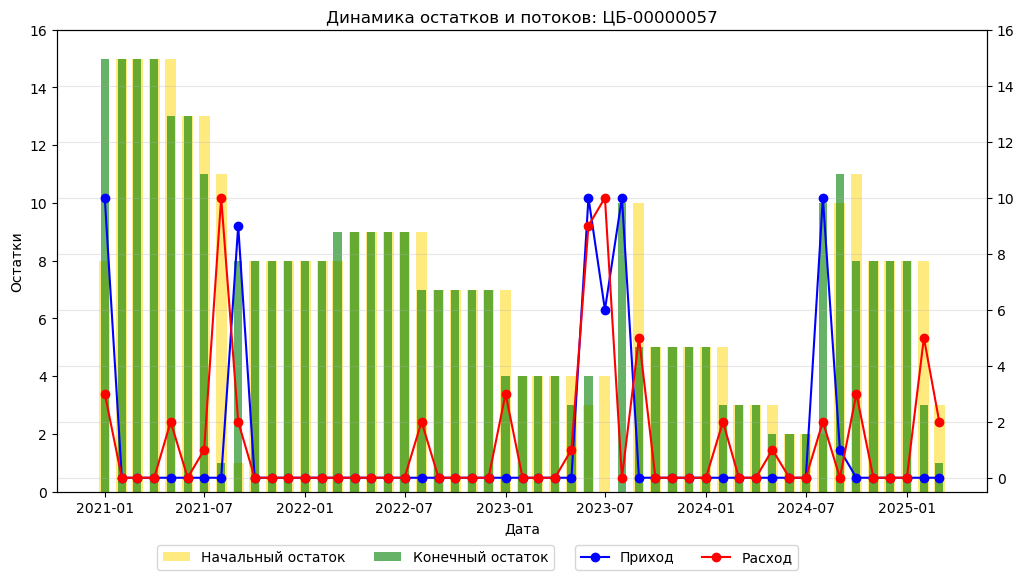

In [92]:
fig, ax1 = plt.subplots(figsize=(12, 6))
ax2 = ax1.twinx()

# Столбчатая диаграмма (начальный и конечный остатки)
ax1.bar(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Начальный_остаток"], color='gold', label='Начальный остаток', width=20, alpha=0.5)
ax1.bar(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Конечный_остаток"], color='green', alpha=0.6, label='Конечный остаток', width=15)

# Линии прихода и расхода
ax2.plot(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Приход"], marker='o', linestyle='-', color='blue', label='Приход')
ax2.plot(df_final_dash_one_kod["Дата"], df_final_dash_one_kod["Расход"], marker='o', linestyle='-', color='red', label='Расход')

# Определяем максимальные значения для оси Y
max_y1 = max(df_final_dash_one_kod["Начальный_остаток"].max(), df_final_dash_one_kod["Конечный_остаток"].max()) + 1
max_y2 = max(df_final_dash_one_kod["Приход"].max(), df_final_dash_one_kod["Расход"].max()) + 1

# Устанавливаем одинаковый масштаб оси Y
max_y = max(max_y1, max_y2)
ax1.set_ylim(0, max_y)  # Ось Y для столбцов
ax2.set_ylim(-0.5, max_y)  # Ось Y для линейных графиков

# Подписи и легенда
#ax1.set_title(f"Динамика остатков и потоков: {item}")
ax1.set_title("Динамика остатков и потоков: ЦБ-00000057")
ax1.set_xlabel("Дата")
ax1.set_ylabel("Остатки")
#ax2.set_ylabel("Приход/Расход", color='red')


# Легенда для столбцов (основная ось)
ax1.legend(loc="upper left", bbox_to_anchor=(0.1, -0.1), ncol=2)

# Легенда для линий (вторичная ось)
ax2.legend(loc="upper left", bbox_to_anchor=(0.55, -0.1), ncol=2)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.show()

In [84]:
df_final_only_sklad = df_final[df_final['Категория'] == 1].sort_values(by=["Номенклатура", "Дата"]).reset_index(drop=True)

In [94]:
len(df_final_only_sklad["Номенклатура"].unique())

2537

In [ ]:
# Уникальные товары
unique_items = df_final_only_sklad["Номенклатура"].unique()

# Создаем графики для каждой номенклатуры
for item in unique_items:
    df_item = df_final_only_sklad[df_final_only_sklad["Номенклатура"] == item]
    
    fig, ax1 = plt.subplots(figsize=(12, 6))
    ax2 = ax1.twinx()
    
    # Столбчатая диаграмма (начальный и конечный остатки)
    ax1.bar(df_item["Дата"], df_item["Начальный_остаток"], color='gold', label='Начальный остаток', width=20, alpha=0.5)
    ax1.bar(df_item["Дата"], df_item["Конечный_остаток"], color='green', alpha=0.6, label='Конечный остаток', width=15)
    
    # Линии прихода и расхода
    ax2.plot(df_item["Дата"], df_item["Приход"], marker='o', linestyle='-', color='blue', label='Приход')
    ax2.plot(df_item["Дата"], df_item["Расход"], marker='o', linestyle='-', color='red', label='Расход')
    
    # Определяем максимальные значения для оси Y
    max_y1 = max(df_item["Начальный_остаток"].max(), df_item["Конечный_остаток"].max()) + 1
    max_y2 = max(df_item["Приход"].max(), df_item["Расход"].max()) + 1

    # Устанавливаем одинаковый масштаб оси Y
    max_y = max(max_y1, max_y2)
    ax1.set_ylim(0, max_y)  # Ось Y для столбцов
    ax2.set_ylim(-0.5, max_y)  # Ось Y для линейных графиков
    
    # Подписи и легенда
    ax1.set_xlabel("Дата")
    ax1.set_ylabel("Остатки")
    ax1.set_title(f"Динамика остатков и потоков: {item[:20]}")
    
    ax1.legend(loc="upper left", bbox_to_anchor=(0.1, -0.1), ncol=2)
    ax2.legend(loc="upper left", bbox_to_anchor=(0.55, -0.1), ncol=2)
    
    plt.xticks(rotation=45)
    plt.grid(alpha=0.3)
    plt.show()

In [ ]:
df_1 = 

In [21]:
df_no_kol = df.loc[:, 
    (df.columns.get_level_values(0).isin(["Артикул", "Номенклатура", "Ед. изм."])) |
    ((df.columns.get_level_values(1) == "Начальный остаток") & 
     (df.columns.get_level_values(2) == "Количество"))
]

In [22]:
df_no_kol

,Артикул,Номенклатура,Ед. изм.,Январь 2021 г.,Февраль 2021 г.,Март 2021 г.,Апрель 2021 г.,Май 2021 г.,Июнь 2021 г.,Июль 2021 г.,...,Июнь 2024 г.,Июль 2024 г.,Август 2024 г.,Сентябрь 2024 г.,Октябрь 2024 г.,Ноябрь 2024 г.,Декабрь 2024 г.,Январь 2025 г.,Февраль 2025 г.,Март 2025 г.
,Unnamed: 0_level_1,Unnamed: 1_level_1,Unnamed: 2_level_1,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,...,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток,Начальный остаток
,Unnamed: 0_level_2,Unnamed: 1_level_2,Unnamed: 2_level_2,Количество,Количество,Количество,Количество,Количество,Количество,Количество,...,Количество,Количество,Количество,Количество,Количество,Количество,Количество,Количество,Количество,Количество
0,0Т-00042714,10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0Т-00039061,10 500 1000 H Royal Thermo (820Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0Т-00042733,10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0Т-00045841,10 500 1100 H Royal Thermo (902Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0Т-00041474,10 500 1200 H Royal Thermo (984Вт) ПОД ЗАКАЗ,шт,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17616,00001197,яяяяяяяяяяХомут 50 для канал серый пластик КОН...,шт,271.0,271.0,263.0,253.0,60.0,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
17617,0Т-00032264,яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...,шт,3.0,3.0,3.0,3.0,3.0,3.0,3.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
df_no_kol.columns = df_no_kol.columns.droplevel(1)
df_no_kol.columns = df_no_kol.columns.droplevel(1)

In [25]:
df_no_kol.columns

Index(['Артикул', 'Номенклатура', 'Ед. изм.', 'Январь 2021 г.',
       'Февраль 2021 г.', 'Март 2021 г.', 'Апрель 2021 г.', 'Май 2021 г.',
       'Июнь 2021 г.', 'Июль 2021 г.', 'Август 2021 г.', 'Сентябрь 2021 г.',
       'Октябрь 2021 г.', 'Ноябрь 2021 г.', 'Декабрь 2021 г.',
       'Январь 2022 г.', 'Февраль 2022 г.', 'Март 2022 г.', 'Апрель 2022 г.',
       'Июнь 2022 г.', 'Июль 2022 г.', 'Август 2022 г.', 'Сентябрь 2022 г.',
       'Октябрь 2022 г.', 'Ноябрь 2022 г.', 'Декабрь 2022 г.',
       'Январь 2023 г.', 'Февраль 2023 г.', 'Март 2023 г.', 'Апрель 2023 г.',
       'Май 2023 г.', 'Июнь 2023 г.', 'Июль 2023 г.', 'Август 2023 г.',
       'Сентябрь 2023 г.', 'Октябрь 2023 г.', 'Ноябрь 2023 г.',
       'Декабрь 2023 г.', 'Январь 2024 г.', 'Февраль 2024 г.', 'Март 2024 г.',
       'Апрель 2024 г.', 'Май 2024 г.', 'Июнь 2024 г.', 'Июль 2024 г.',
       'Август 2024 г.', 'Сентябрь 2024 г.', 'Октябрь 2024 г.',
       'Ноябрь 2024 г.', 'Декабрь 2024 г.', 'Январь 2025 г.',
       'Февр

In [26]:
# Преобразуем таблицу в длинный формат
df_no_kol_long = df_no_kol.melt(id_vars=['Артикул', 'Номенклатура', 'Ед. изм.'], var_name="Дата", value_name="Начальный ост колво")
df_no_kol_long

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный ост колво
0,0Т-00042714,10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
1,0Т-00039061,10 500 1000 H Royal Thermo (820Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
2,0Т-00042733,10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
3,0Т-00045841,10 500 1100 H Royal Thermo (902Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
4,0Т-00041474,10 500 1200 H Royal Thermo (984Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0
...,...,...,...,...,...
881045,00001197,яяяяяяяяяяХомут 50 для канал серый пластик КОН...,шт,Март 2025 г.,NaN
881046,0Т-00032264,яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...,шт,Март 2025 г.,NaN
881047,0Т-00031084,яяяяяяяяяяяяОтвод 110/30 внут Политрон,шт,Март 2025 г.,NaN
881048,0Т-00006458,яяяяяяяяяяяяяяяяяМанометр ТМ-510Р.05 16 кгс/см...,шт,Март 2025 г.,NaN


In [27]:
df_no_kol_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 881050 entries, 0 to 881049
Data columns (total 5 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Артикул              881050 non-null  object 
 1   Номенклатура         881050 non-null  object 
 2   Ед. изм.             881050 non-null  object 
 3   Дата                 881050 non-null  object 
 4   Начальный ост колво  844247 non-null  float64
dtypes: float64(1), object(4)
memory usage: 33.6+ MB


In [28]:
# Функция для присваивания категории
def assign_category(nomenklatura):
    if 'ПОД ЗАКАЗ' in nomenklatura:
        return 1
    elif 'СКЛАД' in nomenklatura:
        return 2
    else:
        return 0

In [30]:
# Создаем новый столбец 'Категория'
df_no_kol_long['Категория'] = df_no_kol_long['Номенклатура'].apply(assign_category)
df_no_kol_long

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный ост колво,Категория
0,0Т-00042714,10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0,1
1,0Т-00039061,10 500 1000 H Royal Thermo (820Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0,1
2,0Т-00042733,10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0,1
3,0Т-00045841,10 500 1100 H Royal Thermo (902Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0,1
4,0Т-00041474,10 500 1200 H Royal Thermo (984Вт) ПОД ЗАКАЗ,шт,Январь 2021 г.,0.0,1
...,...,...,...,...,...,...
881045,00001197,яяяяяяяяяяХомут 50 для канал серый пластик КОН...,шт,Март 2025 г.,NaN,0
881046,0Т-00032264,яяяяяяяяяяяя11 600х1200 CV Purmo (1539 вт 90/7...,шт,Март 2025 г.,NaN,0
881047,0Т-00031084,яяяяяяяяяяяяОтвод 110/30 внут Политрон,шт,Март 2025 г.,NaN,0
881048,0Т-00006458,яяяяяяяяяяяяяяяяяМанометр ТМ-510Р.05 16 кгс/см...,шт,Март 2025 г.,NaN,0


In [32]:
df_no_kol_long[df_no_kol_long['Категория'] == 2][1200:1300]

,Артикул,Номенклатура,Ед. изм.,Дата,Начальный ост колво,Категория
4336,00000221,Пер 1/2нр х 1/2нр никел. Valtec упак 10 шт СКЛ...,шт,Январь 2021 г.,1655.0,2
4339,00005553,Пер 1/2нр х 1/4вн никел. Valtec упак 10 шт (фу...,шт,Январь 2021 г.,46.0,2
4340,00005546,Пер 1/2нр х 1/4нр никел. Valtec упак 10 шт С...,шт,Январь 2021 г.,14.0,2
4341,0Т-00050199,Пер 1/2нр х 3/4нр никел. AQUALINK упак 300/10 ...,шт,Январь 2021 г.,0.0,2
4342,00000225,Пер 1/2нр х 3/4нр никел. Valtec упак 10 шт ...,шт,Январь 2021 г.,169.0,2
...,...,...,...,...,...,...
4459,0Т-00034668,Переход 32/50 концентрический внут РТП СКЛАД...,шт,Январь 2021 г.,0.0,2
4461,0Т-00033362,Переход 110/50 внут РТП СКЛАД (400) упак 60/1 шт,шт,Январь 2021 г.,0.0,2
4462,0Т-00031331,Переход 110/50 внутренний ВОССТАНОВИТЕЛЬ РАСТР...,шт,Январь 2021 г.,0.0,2
4463,0Т-00024629,Переход 110/50 Контур (СКЛАД 50) консигн.,шт,Январь 2021 г.,20.0,2


In [33]:
df_no_kol_long['Номенклатура'].unique().tolist()

['10 300 500 H EVRA (269Вт) ПОД ЗАКАЗ',
 '10 500 1000 H  Royal Thermo (820Вт) ПОД ЗАКАЗ',
 '10 500 1000 H EVRA (835Вт) ПОД ЗАКАЗ',
 '10 500 1100 H  Royal Thermo (902Вт) ПОД ЗАКАЗ',
 '10 500 1200 H  Royal Thermo (984Вт) ПОД ЗАКАЗ',
 '10 500 1200 H EVRA (1002Вт) ПОД ЗАКАЗ',
 '10 500 1200 HV EVRA (825 вт) ПОД ЗАКАЗ',
 '10 500 1300 H  Royal Thermo (1066Вт) ПОД ЗАКАЗ',
 '10 500 1400 H  Royal Thermo (1148Вт) ПОД ЗАКАЗ',
 '10 500 1400 H EVRA (1169Вт) ПОД ЗАКАЗ',
 '10 500 1500 H  Royal Thermo (1230Вт) ПОД ЗАКАЗ',
 '10 500 1600 H  Royal Thermo (1312Вт) ПОД ЗАКАЗ',
 '10 500 1600 H EVRA (1336Вт) ПОД ЗАКАЗ',
 '10 500 1700 H  Royal Thermo (1394Вт) ПОД ЗАКАЗ',
 '10 500 400 H  Royal Thermo (328Вт) ПОД ЗАКАЗ',
 '10 500 400 H EVRA (334Вт) ПОД ЗАКАЗ',
 '10 500 500 H  Royal Thermo (410Вт) ПОД ЗАКАЗ',
 '10 500 600 H  Royal Thermo (492Вт) ПОД ЗАКАЗ',
 '10 500 700 H  Royal Thermo (574Вт) ПОД ЗАКАЗ',
 '10 500 800 H  Royal Thermo (656Вт) ПОД ЗАКАЗ',
 '10 500 900 H  Royal Thermo (738Вт) ПОД ЗАКАЗ',
 '10 500 90

In [ ]:
# После этого делаем melt
# Так создаем все нужные датасеты
# потом присоединяем все датасеты в один по артикулу и ДАТЕ!!